# 02 · Retrieval evaluation — Musta'jir

**Purpose.** Show, with measurements, how each retrieval design decision was made: chunking, contextual
prefixes, dense vs. sparse vs. hybrid, metadata filters, cross-encoder reranking, citation lookup, and
the embedding model.

**Method.** 50 gold questions, each labelled with the *binding provision* that must be cited
(`primary_ids`) and all acceptable evidence (`relevant_ids`). Hyper-parameters were chosen on the
**15-question dev split only**; the **35-question test split** is reported as held-out.
All numbers below are read from `data/eval/runs/` - regenerate them with
`python -m tenancy_rag eval-retrieval` (GPU recommended for the reranker rows).

Contents: 1 Setup · 2 Metrics · 3 Ablation grid · 4 Why filters must precede the reranker · 5 Tuning on dev ·
6 Citation lookup (lexical probe) · 7 Embedding model selection · 8 Error analysis · 9 Live demo (optional)

## 1 · Setup

In [1]:
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import userdata
    if not Path("dubai-tenancy-assistant").exists():
        try:   # a read-only token is only needed if the repository is private
            auth = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:
            auth = ""
        subprocess.run(["git", "clone", f"https://{auth}github.com/bettinacodes/dubai-tenancy-assistant.git"], check=True)
    os.chdir("dubai-tenancy-assistant")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    sys.path.insert(0, "src")
else:
    root = Path.cwd()
    while not (root / "pyproject.toml").exists():
        root = root.parent
    os.chdir(root); sys.path.insert(0, str(root / "src"))

import json
import pandas as pd
import matplotlib.pyplot as plt
from tenancy_rag import config
RUNS = config.EVAL / "runs"
load_run = lambda name: json.loads((RUNS / f"retrieval__{name}.json").read_text(encoding="utf-8"))
gold = [json.loads(l) for l in open(config.EVAL / "gold.jsonl", encoding="utf-8")]
parents = {json.loads(l)["parent_id"]: json.loads(l) for l in open(config.PROCESSED / "parents.jsonl", encoding="utf-8")}
print(len(gold), "gold questions;", sum(g["split"] == "dev" for g in gold), "dev /", sum(g["split"] == "test" for g in gold), "test")

50 gold questions; 15 dev / 35 test


## 2 · Metrics (article level)
Rankings of chunks are collapsed to rankings of *parents* (article / FAQ pair / page) because the parent is what gets cited.
* **primary@k** - is the binding provision in the top-k? *(the metric that matters most: can the system cite the law?)*
* **hit@k** - is any acceptable source in the top-k? · **MRR@10**, **nDCG@10** (primary = gain 2, other relevant = 1).

## 3 · Ablation grid (held-out test split, n = 35)

In [2]:
ROWS = [("0", "No retrieval (LLM only)", None),
        ("1", "Dense bge-m3", "hyb~1_dense"), ("2", "BM25 (legal tokeniser)", "hyb~2_bm25"),
        ("3", "Hybrid RRF", "hyb~3_hybrid_rrf"), ("3f", "Hybrid + filters", "hyb~4f_hybrid_filters"),
        ("4", "Hybrid + reranker (no filters)", "hyb~4_hybrid_rerank"),
        ("4f", "Hybrid + filters + reranker", "hyb~4fr_hybrid_filters_rerank"),
        ("F", "FINAL: dense + filters + reranker + lookup", "hyb~final"),
        ("5", "Row 4 with fixed 512-token chunks", "hyb~5_fixed512"),
        ("6", "Row 4 without contextual prefixes", "hyb~6_no_prefix")]
tbl = []
for rid, label, name in ROWS:
    if name is None:
        tbl.append({"row": rid, "configuration": label, "primary@1": 0.0, "primary@10": 0.0, "hit@10": None, "mrr@10": None, "ms/q": None}); continue
    r = load_run(name); a = r["test"]
    tbl.append({"row": rid, "configuration": label, "primary@1": a["primary@1"], "primary@10": a["primary@10"],
                "hit@10": a["hit@10"], "mrr@10": a["mrr@10"], "ms/q": r["ms_per_query"]})
grid = pd.DataFrame(tbl).set_index("row")
grid.round(2)

,configuration,primary@1,primary@10,hit@10,mrr@10,ms/q
row,,,,,,
0,No retrieval (LLM only),0.00,0.00,NaN,NaN,NaN
1,Dense bge-m3,0.26,0.85,0.94,0.66,3.6
2,BM25 (legal tokeniser),0.07,0.56,0.69,0.41,0.2
3,Hybrid RRF,0.22,0.81,0.86,0.61,4.0
3f,Hybrid + filters,0.33,0.81,0.86,0.66,4.0
4,Hybrid + reranker (no filters),0.11,0.81,0.86,0.56,2558.3
4f,Hybrid + filters + reranker,0.30,0.81,0.86,0.63,2150.8
F,FINAL: dense + filters + reranker + lookup,0.33,0.85,0.94,0.68,2410.3
5,Row 4 with fixed 512-token chunks,0.04,0.52,0.74,0.39,4017.6


Row 0 is the measured no-retrieval baseline from Day 3: the LLM cited the correct provision in **0 of 39** answerable questions (both 3B and 7B models). Latency in rows with a reranker is dominated by the cross-encoder on a 4 GB GTX 1650 in fp32 (fp16 is 5.5x slower on this card.4).

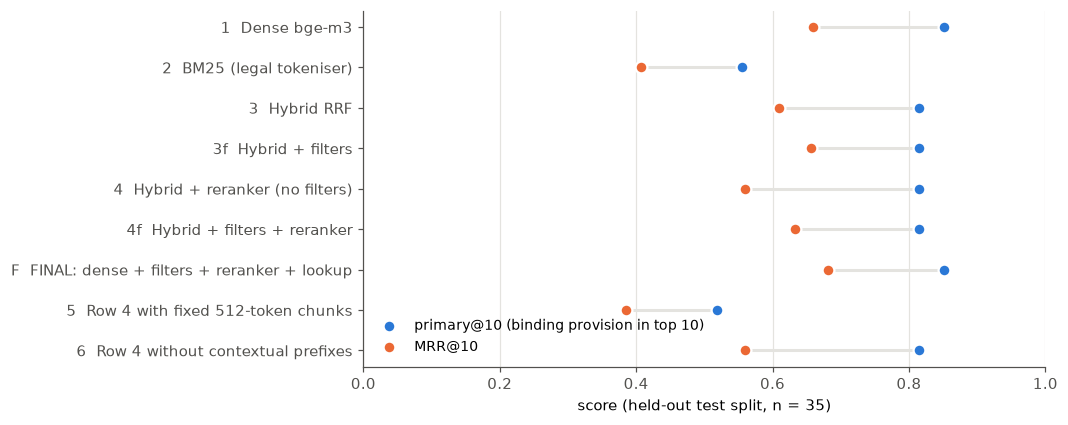

In [3]:
TIER = "#2a78d6"; ALT = "#eb6834"; INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
FIG = config.ROOT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
g = grid.drop(index="0").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
y = range(len(g))
ax.hlines(y, g["mrr@10"], g["primary@10"], color=GRID, linewidth=2, zorder=1)
ax.scatter(g["primary@10"], y, s=60, color=TIER, edgecolor="white", linewidth=1.5, zorder=3, label="primary@10 (binding provision in top 10)")
ax.scatter(g["mrr@10"], y, s=60, color=ALT, edgecolor="white", linewidth=1.5, zorder=3, label="MRR@10")
ax.set_yticks(list(y), [f"{i}  {c}" for i, c in zip(g.index, g["configuration"])])
ax.set_xlim(0, 1); ax.set_xlabel("score (held-out test split, n = 35)"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.savefig(FIG / "fig7_1_ablation_grid.png"); plt.show()

**Reading the grid**
* Structure-aware chunking is decisive (row 5 vs 4): fixed windows halve primary@10.
* Dense retrieval beats BM25 by a wide margin (row 1 vs 2) - tenants do not use statutory vocabulary.
* Equal-weight fusion does not help (row 3 vs 1); BM25 only contributes on exact-reference queries (§6).
* **The reranker without filters hurts** (row 4 primary@1) - see §4.

## 4 · Why status filters must come *before* the reranker

In [4]:
def leak(run, k=5):
    pq = load_run(run)["per_query"]
    return sum(any(parents[p]["status"] == "superseded" for p in q["top10"][:k]) for q in pq) / len(pq)
lk = pd.DataFrame({"superseded provision in top-5 (share of 50 questions)":
                   {"dense, no filter": leak("dense__struct-noprefix"), "hybrid + reranker, no filter": leak("hyb~4_hybrid_rerank"),
                    "final (filters)": leak("hyb~final")}})
lk.round(2)

,superseded provision in top-5 (share of 50 questions)
"dense, no filter",0.46
"hybrid + reranker, no filter",0.42
final (filters),0.00


Without status metadata, superseded 2007 articles reach the top-5 for roughly half of all questions, and the
cross-encoder makes it *worse*: the original and amended texts are near-identical, so a relevance model ranks the
outdated one highly. Relevance cannot detect obsolescence - only metadata can. In the final configuration superseded
text is removed from the current-law ranking (kept separately for "what changed?" questions).

## 5 · Tuning on the dev split (15 questions)

In [5]:
tune = pd.DataFrame([json.loads(l) for l in open(RUNS / "tuning_log.jsonl", encoding="utf-8")])
tune["config"] = tune.cfg.map(lambda c: f"bm25={c['bm25']} w={c['bm25_weight']} k={c['rrf_k']} rerank={c['rerank']}(n={c['rerank_n']}) expand={c['expand']}({c['expand_min_sim']})")
tune[["stage", "config", "primary@1", "primary@30", "recall@30", "mrr@10", "ms_per_query"]].round(2)

,stage,config,primary@1,primary@30,recall@30,mrr@10,ms_per_query
0,A,bm25=False w=1.0 k=60 rerank=False(n=30) expan...,0.33,0.92,0.97,0.64,4
1,A,bm25=True w=0.25 k=20 rerank=False(n=30) expan...,0.33,0.92,0.95,0.62,4
2,A,bm25=True w=0.25 k=60 rerank=False(n=30) expan...,0.33,0.92,0.95,0.60,4
3,A,bm25=True w=0.5 k=20 rerank=False(n=30) expand...,0.33,0.92,0.95,0.62,4
4,A,bm25=True w=0.5 k=60 rerank=False(n=30) expand...,0.33,0.92,0.95,0.61,4
5,A,bm25=True w=1.0 k=20 rerank=False(n=30) expand...,0.25,0.92,0.90,0.60,4
6,A,bm25=True w=1.0 k=60 rerank=False(n=30) expand...,0.25,0.92,0.90,0.60,4
7,B,bm25=True w=0.5 k=20 rerank=True(n=10) expand=...,0.33,0.92,0.95,0.72,3142
8,B,bm25=True w=0.5 k=20 rerank=True(n=20) expand=...,0.25,0.92,0.95,0.73,3519
9,B,bm25=True w=0.5 k=20 rerank=True(n=30) expand=...,0.25,0.92,0.95,0.73,4780


One dev question moves a metric by 0.067, so differences smaller than that were treated as ties and broken toward the
simpler/faster option. Decisions: RRF k = 20 over 60; reranker depth 10 (equal to 30, faster); authority-aware
expansion **rejected** (no effect once a cross-encoder reranks); BM25 dropped from the final first stage (tie on dev;
exact-reference queries are handled by the citation lookup instead - §6). The test split was consistent with these choices.

## 6 · Exact references are a lookup, not a search (lexical probe)

In [6]:
probe = pd.DataFrame(json.loads((RUNS / "lexical_probe.json").read_text(encoding="utf-8"))).T
probe[["primary@1", "primary@10", "mrr@10", "not_first"]]

,primary@1,primary@10,mrr@10,not_first
dense only,0.25,0.625,0.3958,"[L1, L2, L3, L5, L6, L7]"
rrf w=0.25 k=20,0.25,0.75,0.4323,"[L1, L2, L3, L5, L6, L7]"
rrf w=0.5 k=20,0.375,0.75,0.5179,"[L1, L3, L5, L6, L7]"
rrf w=1.0 k=60,0.5,0.75,0.5875,"[L1, L3, L5, L6]"
dense only + lookup,0.625,0.875,0.7292,"[L5, L6, L7]"
rrf w=0.5 k=20 + lookup,0.625,1.0,0.7679,"[L5, L6, L7]"


Eight probe queries such as *"What does Article 26 of Law 26/2007 say?"* - absent from the gold set. Dense retrieval ranks the
named article first only 25% of the time; the deterministic **citation lookup** (parse article + instrument, return the
*current* version) lifts MRR from 0.40 to 0.73. The remaining misses name no instrument and are left to search.

## 7 · Embedding model selection (English gold questions)

In [7]:
emb = pd.DataFrame({m: {**{k: load_run(n)[s][k] for s in ("test",) for k in ("hit@10", "primary@10", "mrr@10")}}
                    for m, n in [("all-MiniLM-L6-v2 (English-only)", "dense-minilm__struct-noprefix"),
                                 ("multilingual-e5-large", "dense-e5__struct-noprefix"),
                                 ("bge-m3 (chosen)", "dense__struct-noprefix")]}).T
emb.round(2)

,hit@10,primary@10,mrr@10
all-MiniLM-L6-v2 (English-only),0.86,0.85,0.60
multilingual-e5-large,0.89,0.85,0.59
bge-m3 (chosen),0.94,0.85,0.66


On English questions the three models are within one or two questions of each other; bge-m3 leads on hit@10 and MRR.
The deciding requirement is **multilingual retrieval** (the users are expatriates; MiniLM is English-only) - measured on
the Arabic/Hindi parity set in notebook 03.

## 8 · Error analysis (final configuration)

In [8]:
fin = {q["id"]: q for q in load_run("hyb~final")["per_query"]}
G = {g["id"]: g for g in gold}
miss = [q for q in fin.values() if q.get("primary@10") == 0]
pd.DataFrame([{"id": q["id"], "style": q["style"], "question": G[q["id"]]["question"][:70],
               "wanted": G[q["id"]]["primary_ids"][0], "got (top 3)": ", ".join(q["top10"][:3])} for q in miss])

,id,style,question,wanted,got (top 3)
0,G07,colloquial,My contract ends on 1 December 2026 and the la...,dubai-law-26-2007__art-14__as-amended-L33-2008,"dld-faq__q-104, dld-faq__q-156, dld-faq__q-25"
1,G25,colloquial,"When I move out, do I have to fix small scratc...",dubai-law-26-2007__art-21,"dld-faq__q-27, rdc-faq__q-84, dubai-law-26-200..."
2,G30,plain,Is it compulsory to register my tenancy contra...,dubai-law-26-2007__art-4__as-amended-L33-2008,"dld-tenancy-guide__p-4, dld-faq__q-71, dld-faq..."
3,G36,colloquial,How many months of rent is the penalty for end...,dubai-law-26-2007__art-7,"dld-faq__q-80, rdc-faq__q-87, dubai-law-26-200..."
4,G49,colloquial,My landlord cut off the electricity and water ...,dubai-law-26-2007__art-34,"dld-faq__q-22, dld-faq__q-153, dld-faq__q-23"


The remaining misses are mostly *paraphrase crowding*: an FAQ answer that restates the article is ranked above it. The answer is still grounded (the FAQ is acceptable evidence), but the citation should point to the law - the generator is instructed to prefer binding provisions and the validator checks citations (Day 7).

## 9 · Live demo (optional - needs the models; GPU recommended)

In [9]:
RUN_LIVE = False
if RUN_LIVE:
    from tenancy_rag.retrieve.hybrid import HybridRetriever, preset
    from tenancy_rag.eval.retrieval_metrics import parents_from_chunks
    r = HybridRetriever(preset("final"))
    for q in ["Can my landlord evict me at the end of my lease because he wants to sell?",
              "What does Article 26 of Law 26/2007 say?"]:
        print(q); [print("  ", p, "-", parents[p]["status"]) for p in parents_from_chunks(r.search(q, k=10))[:5]]
        print("   historical (superseded) candidates:", [c["parent_id"] for c in r.last_historical][:3])